# Analytical Gold demo

Explore how daily electricity consumption relates to temperature and spot prices across Norwegian price areas and consumer groups (2024–2025).

This notebook reads existing Gold data.

## Setup and load Gold data

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

PROJECT_ROOT = Path.cwd().parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

spark = (SparkSession.builder
         .appName("Analytical Gold Demo")
         .master("local[4]")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.session.timeZone", "UTC")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

path = PROJECT_ROOT / "data/gold/analytics/daily"
analytics = spark.read.parquet(str(path))
print("Rows:", analytics.count())
analytics.printSchema()

26/11/21 23:15:01 WARN Utils: Your hostname, homelab resolves to a loopback address: 127.0.1.1; using 192.168.10.53 instead (on interface lan0)
26/11/21 23:15:01 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/21 23:15:02 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/21 23:15:02 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/11/21 23:15:02 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/11/21 23:15:02 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.
26/11/21 23:15:02 WARN Utils: Service 'SparkUI' could not bind on port 4043. Attempting port 4044.
26/11/21 23:15:02 WARN Utils: Service 'SparkUI' could not bind on port 4044. Attempting port 4045.


Rows: 18275
root
 |-- date: date (nullable = true)
 |-- price_area: string (nullable = true)
 |-- consumption_group: string (nullable = true)
 |-- consumption_kwh: decimal(28,6) (nullable = true)
 |-- avg_temperature_c: decimal(34,22) (nullable = true)
 |-- avg_spot_price_nok_kwh: double (nullable = true)
 |-- consumption_hour_count: integer (nullable = true)
 |-- consumption_is_complete: boolean (nullable = true)
 |-- station_count: long (nullable = true)
 |-- price_hour_count: integer (nullable = true)
 |-- price_is_complete: boolean (nullable = true)



## Daily consumption over time

Plot the total daily consumption across all five consumer groups in each price area. This shows seasonal patterns.

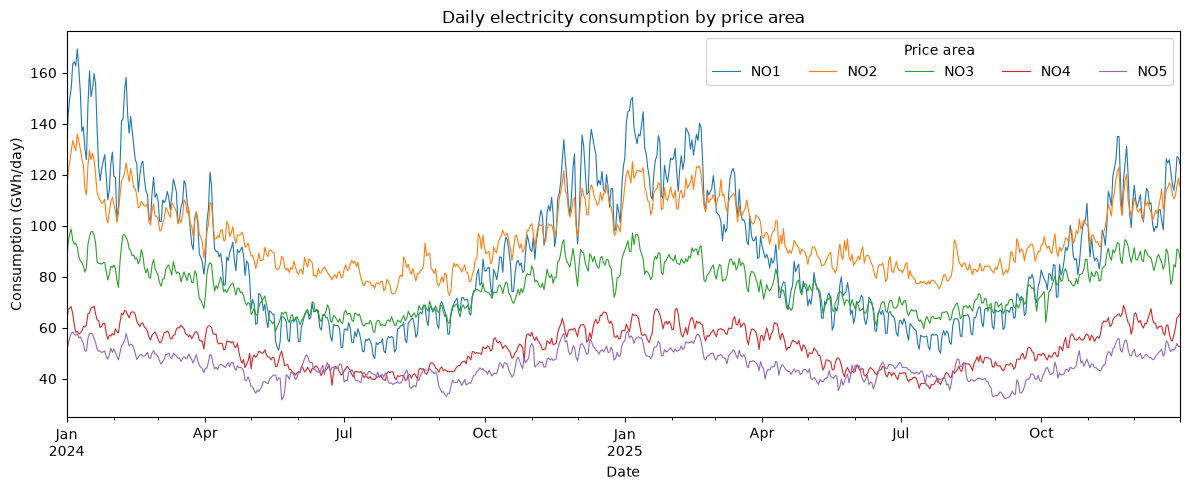

In [ ]:
daily_area = (analytics.groupBy("date", "price_area")
              .agg(F.sum("consumption_kwh").cast("double").alias("consumption_kwh"))
              .orderBy("date", "price_area"))

p = daily_area.toPandas()
p["date"] = pd.to_datetime(p["date"])
pivot = p.pivot(index="date", columns="price_area", values="consumption_kwh") / 1_000_000

ax = pivot.plot(figsize=(12, 5), linewidth=0.8)
ax.set(title="Daily electricity consumption by price area", xlabel="Date", ylabel="Consumption (GWh/day)")
ax.legend(title="Price area", ncol=5)
plt.tight_layout()
plt.show()

## Consumption by consumer group

Compare the share of total consumption to each consumer group within each price area.

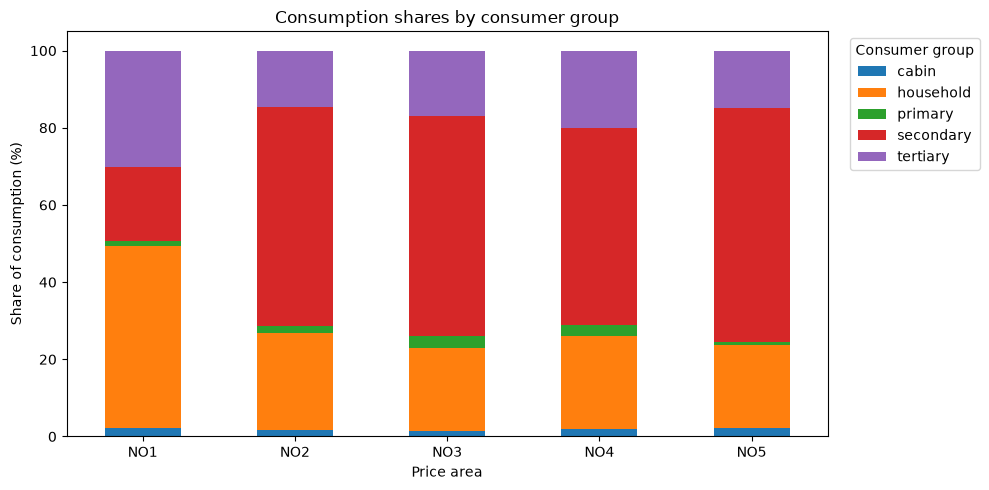

Consumption shares (%):
consumption_group  cabin  household  primary  secondary  tertiary
price_area                                                       
NO1                  2.3       47.1      1.2       19.1      30.3
NO2                  1.7       25.1      1.9       56.6      14.7
NO3                  1.4       21.6      2.9       57.1      16.9
NO4                  1.9       24.3      2.8       51.1      19.9
NO5                  2.1       21.5      0.8       60.8      14.9


In [ ]:
groups = (analytics.groupBy("price_area", "consumption_group")
          .agg(F.sum("consumption_kwh").cast("double").alias("kwh")))

g = groups.toPandas()

shares = g.pivot(index="price_area", columns="consumption_group", values="kwh")
shares = shares.div(shares.sum(axis=1), axis=0) * 100
ax = shares.sort_index().plot(kind="bar", stacked=True, figsize=(10, 5))
ax.set(title="Consumption shares by consumer group", xlabel="Price area", ylabel="Share of consumption (%)")
ax.legend(title="Consumer group", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Consumption shares (%):")
print(shares.round(1).to_string())

## Temperature versus household consumption

Each dot represents one day in a price area. The temperature is an equal-weight average of qualifying weather stations. Temperature and consumption can both vary by season.

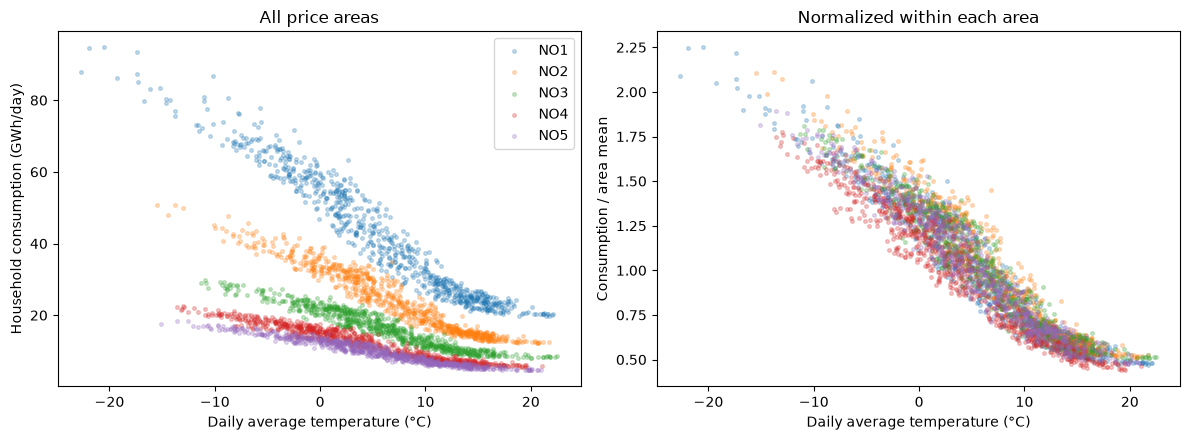

In [ ]:
households = (analytics.filter(F.col("consumption_group") == "household")
              .select("date", "price_area",
                      F.col("consumption_kwh").cast("double").alias("consumption_kwh"),
                      F.col("avg_temperature_c").cast("double").alias("temperature_c")))
h = households.toPandas()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for area in ["NO1", "NO2", "NO3", "NO4", "NO5"]:
    subset = h[h["price_area"] == area]
    axes[0].scatter(subset["temperature_c"], subset["consumption_kwh"] / 1_000_000, s=7, alpha=0.25, label=area)

axes[0].set(xlabel="Daily average temperature (°C)", ylabel="Household consumption (GWh/day)",
            title="All price areas")

axes[0].legend()

# Within area view removes the large differences in absolute consumption scale.
for area in ["NO1", "NO2", "NO3", "NO4", "NO5"]:
    subset = h[h["price_area"] == area]
    baseline = subset["consumption_kwh"].mean()
    axes[1].scatter(subset["temperature_c"], subset["consumption_kwh"] / baseline, s=7, alpha=0.25, label=area) 

axes[1].set(xlabel="Daily average temperature (°C)", ylabel="Consumption / area mean", title="Normalized within each area")

plt.tight_layout()
plt.show()

## Spot price versus household consumption

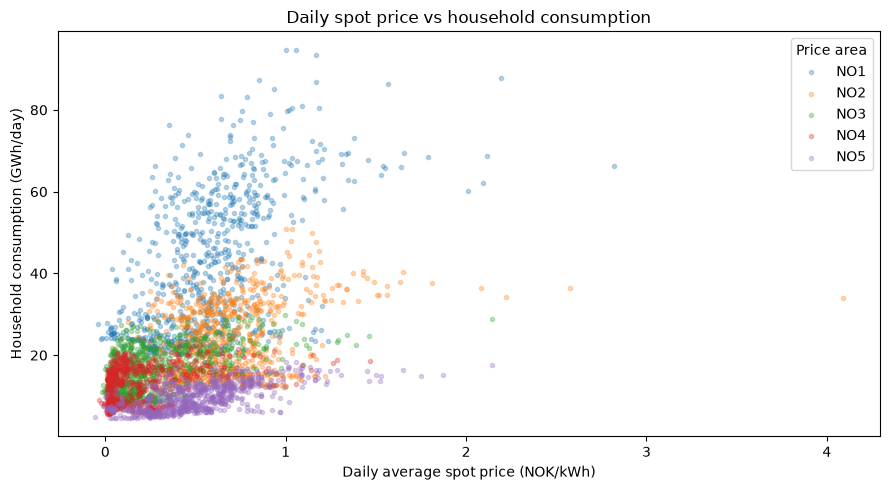

In [ ]:
prices = (analytics.filter((F.col("consumption_group") == "household") &
                           (F.col("price_is_complete") == True))
          .select("price_area",
                  F.col("consumption_kwh").cast("double").alias("consumption_kwh"),
                  F.col("avg_spot_price_nok_kwh").cast("double").alias("price")))

q = prices.toPandas()

fig, ax = plt.subplots(figsize=(9, 5))
for area in ["NO1", "NO2", "NO3", "NO4", "NO5"]:
    subset = q[q["price_area"] == area]
    ax.scatter(subset["price"], subset["consumption_kwh"] / 1_000_000,
               s=9, alpha=0.3, label=area)

ax.set(title="Daily spot price vs household consumption", xlabel="Daily average spot price (NOK/kWh)",
       ylabel="Household consumption (GWh/day)")

ax.legend(title="Price area")
plt.tight_layout()
plt.show()